# Imports

In [1]:
%load_ext autoreload
%autoreload 2

import sys
sys.path.append('..') # path to the root directory
sys.path.append('../..') # path to the root directory
sys.path.append('../../src') # path to the src directory

# Change these lines to match your local directory structure
# sys.path.append('/Users/xz498/Library/CloudStorage/OneDrive-DrexelUniversity/Chang Lab - Documents/General/Individual/Xinqiao Zhang/data_analysis/ultrasonicTesting/')
# sys.path.append('/Users/xz498/Library/CloudStorage/OneDrive-DrexelUniversity/Chang Lab - Documents/General/Individual/Xinqiao Zhang/data_analysis/ultrasonic_ml/src/')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

## Import Data

`AcousticDatabase` contains methods to open sqlite file, convert parameters from dict to hdf5 attr friendly format, and setup groups and datasets for raw and preprocessed. Does not contain methods for indexing and retrieving data. These will be specific to the type of experiment we have.

`AcousticScanDatabase` inherits from `AcousticDatabase`. Inherits setup and filing functions for raw and preprocessed. Write your own indexing and filling methods.

In [2]:
# load the database class
import ultrasonic_ml.data.acoustic_datasets as db
from pathlib import Path

# NOTE: make sure this is only open in one notebook at a time, otherwise the database will be locked and you will not be able to access it.
singleroll_filepath = '/Users/xz498/Library/CloudStorage/OneDrive-DrexelUniversity/Chang Lab - Documents/General/Group/Data/Ultrasound/General Motors/Prismatic Data/091626_singleroll_scan_1mm_multiplexer.sqlite3'
dualroll_filepath = '/Users/xz498/Library/CloudStorage/OneDrive-DrexelUniversity/Chang Lab - Documents/General/Group/Data/Ultrasound/General Motors/Prismatic Data/092226_dualroll_scan_1mm_multiplexer.sqlite3'

p = Path(dualroll_filepath)

h5_name = p.stem+'.h5'
parent_folder = str(p.parent)


In [3]:
# Initialize the acoustic scan database
database = db.AcousticScanDatabaseFFT(parent_folder=parent_folder, 
                                    h5_name=h5_name, 
                                    sqlite_path=dualroll_filepath)

Establishing SQLite connection to database...
Loading h5 parameters...
	Finished.


In [4]:
# Look at sqlite database structure if you want
database.print_sqlite_schema()

├── parameters
│   ├── gui
│   ├── experiment
│   ├── axis
│   ├── distance
│   ├── transducerFrequency
│   ├── collectionMode
│   ├── pulserType
│   ├── measureTime
│   ├── measureDelay
│   ├── voltageRange
│   ├── autoRange
│   ├── autoRangeEcho
│   ├── waves
│   ├── samples
│   ├── halfCycles
│   ├── multiplexer
│   ├── collectionDirection
│   ├── voltageOffsetForward
│   ├── voltageOffsetReverse
│   ├── gainForward
│   ├── gainReverse
│   ├── picoModule
│   ├── pulseModule
│   ├── rfSwitch
│   ├── t0PulseSwitch
│   ├── t0ReceiveSwitch
│   ├── t1PulseSwitch
│   ├── t1ReceiveSwitch
│   ├── experimentFolder
│   ├── experimentName
│   ├── experimentBaseName
│   ├── saveFormat
│   ├── postAnalysis
│   ├── primaryAxis
│   ├── secondaryAxis
│   ├── primaryAxisRange
│   ├── primaryAxisStep
│   ├── secondaryAxisRange
│   ├── secondaryAxisStep
│   ├── scanInterval
│   ├── numberOfScans
│   ├── pulseInterval
│   ├── experimentTime
│   ├── sweepParams
│   ├── pulserPort
│   ├── scannerPort
│  

The first time you run this, you will have to run setup functions to write metadata, fill raw data, and indexing related parameters

In [16]:
# Run ONCE
# setup and fill the raw data group from sqlite file. 
database.sqlite_to_h5()

Filling raw data: 100%|██████████| 9362/9362 [01:11<00:00, 131.58it/s]


Writing indexed parameters: ['collection_index', 'time_collected', 'X', 'Z']


2it [00:09,  4.54s/it]

	Finished
	Finished


In [17]:
# look at parameter setup if you want
database.print_parameters()

{   'autoRangeEcho': {   'description': 'Set the oscilloscope to rerun '
                                        'measurements where the voltage range '
                                        'of the wave has significantly '
                                        'changed. This enables the tightest '
                                        'possible voltageRange to be used, '
                                        'increasing the accuracy of low '
                                        'intensity signals without cutting off '
                                        'high intensity ones. For echo '
                                        'measurements, this can add '
                                        'significant overhead (2-3x increase '
                                        'in collection time) for each waveform '
                                        'where the range changes',
                         'value': 'False'},
    'collectionDirection': {   'description': 'for

In [74]:
# look at the h5 database structure
database.print_schema()

<HDF5 file "092226_dualroll_scan_1mm_multiplexer.h5" (mode r+)>
|--<HDF5 dataset "config_metadata": shape (), type "|O"> [0.00 MB]
|--<HDF5 group "/first_break_aligned" (5 members)>
|  |--<HDF5 dataset "amplitude": shape (2, 151, 31), type "<f4"> [0.04 MB]
|  |--<HDF5 dataset "hilbert": shape (2, 151, 31, 13795), type "<f4"> [492.66 MB]
|  |--<HDF5 dataset "tof": shape (2, 151, 31), type "<f4"> [0.04 MB]
|  |--<HDF5 dataset "waveforms": shape (2, 151, 31, 13795), type "<f4"> [492.66 MB]
|  |--<HDF5 dataset "x_corr": shape (2, 151, 31, 13795), type "<f4"> [492.66 MB]
|--<HDF5 group "/indexed_parameters" (2 members)>
|  |--<HDF5 dataset "collection_index": shape (151, 31), type "<f4"> [0.02 MB]
|  |--<HDF5 dataset "time_collected": shape (151, 31), type "<f4"> [0.02 MB]
|--<HDF5 group "/raw_data" (2 members)>
|  |--<HDF5 dataset "hilbert": shape (2, 151, 31, 25000), type "<f4"> [0.00 MB]
|  |--<HDF5 dataset "waveforms": shape (2, 151, 31, 25000), type "<f4"> [892.83 MB]


## Preprocessing

Current functioning: applying a butterworth filter.

Rolling back gain and offset is WIP.

In [75]:
# Run ONCE
# setup and fill the preprocessed data group from raw data.
database.write_preprocessed_data(apply_ungain = False, apply_filter=True, 
                                 lower_fs_coeff = 1/250, upper_fs_coeff = 1/5, filter_order = 3)

Writing preprocessed data: 100%|██████████| 9362/9362 [00:19<00:00, 484.28it/s]

	Finished


In [76]:
# look at the h5 database structure now
database.print_schema()

<HDF5 file "092226_dualroll_scan_1mm_multiplexer.h5" (mode r+)>
|--<HDF5 dataset "config_metadata": shape (), type "|O"> [0.00 MB]
|--<HDF5 group "/first_break_aligned" (5 members)>
|  |--<HDF5 dataset "amplitude": shape (2, 151, 31), type "<f4"> [0.04 MB]
|  |--<HDF5 dataset "hilbert": shape (2, 151, 31, 13795), type "<f4"> [492.66 MB]
|  |--<HDF5 dataset "tof": shape (2, 151, 31), type "<f4"> [0.04 MB]
|  |--<HDF5 dataset "waveforms": shape (2, 151, 31, 13795), type "<f4"> [492.66 MB]
|  |--<HDF5 dataset "x_corr": shape (2, 151, 31, 13795), type "<f4"> [492.66 MB]
|--<HDF5 group "/indexed_parameters" (2 members)>
|  |--<HDF5 dataset "collection_index": shape (151, 31), type "<f4"> [0.02 MB]
|  |--<HDF5 dataset "time_collected": shape (151, 31), type "<f4"> [0.02 MB]
|--<HDF5 group "/preprocessed_data" (2 members)>
|  |--<HDF5 dataset "hilbert": shape (2, 151, 31, 25000), type "<f4"> [892.83 MB]
|  |--<HDF5 dataset "waveforms": shape (2, 151, 31, 25000), type "<f4"> [892.83 MB]
|--<HD

/Users/xz498/Library/CloudStorage/OneDrive-DrexelUniversity/Chang Lab - Documents/General/Individual/Xinqiao Zhang/data_analysis/ultrasonic_ml/Notebooks/fft/../../src/ultrasonic_ml/data/acoustic_datasets.py:1714: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  print('\tFinished')


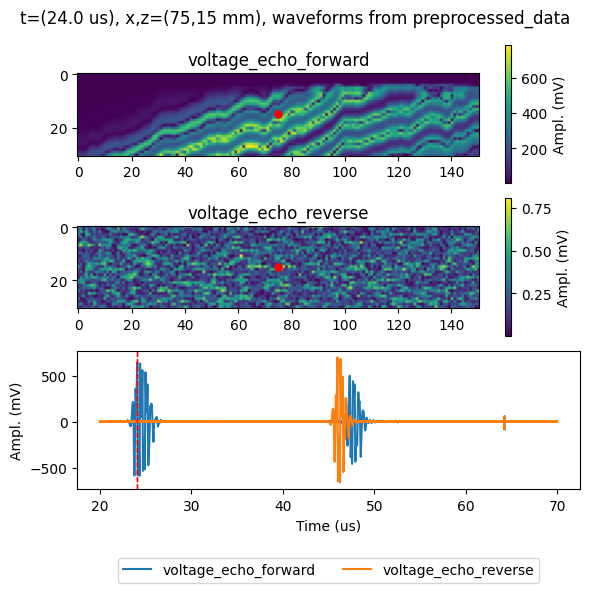

In [77]:
# Look at basic view of mean image and spectrum of data
database.view_img_plot(idx = (75,15,2000), from_group='preprocessed_data', from_dataset='waveforms')

## Match first break

If we are looking at a scan of a battery, from 2 sides, it would be useful to line up the first break of the waveforms. We can do this and delete old datasets that we don't need

In [78]:
# RUN ONCE
# align forward and reverse waveforms to first break and save to h5.
database.write_first_break_aligned_data(from_group='preprocessed_data')

Aligning first break: 100%|██████████| 9362/9362 [00:05<00:00, 1587.94it/s]


	Finished


In [79]:
# look at the h5 database structure now
database.print_schema()

<HDF5 file "092226_dualroll_scan_1mm_multiplexer.h5" (mode r+)>
|--<HDF5 dataset "config_metadata": shape (), type "|O"> [0.00 MB]
|--<HDF5 group "/first_break_aligned" (5 members)>
|  |--<HDF5 dataset "amplitude": shape (2, 151, 31), type "<f4"> [0.04 MB]
|  |--<HDF5 dataset "hilbert": shape (2, 151, 31, 13795), type "<f4"> [492.66 MB]
|  |--<HDF5 dataset "tof": shape (2, 151, 31), type "<f4"> [0.04 MB]
|  |--<HDF5 dataset "waveforms": shape (2, 151, 31, 13795), type "<f4"> [492.66 MB]
|  |--<HDF5 dataset "x_corr": shape (2, 151, 31, 13795), type "<f4"> [492.66 MB]
|--<HDF5 group "/indexed_parameters" (2 members)>
|  |--<HDF5 dataset "collection_index": shape (151, 31), type "<f4"> [0.02 MB]
|  |--<HDF5 dataset "time_collected": shape (151, 31), type "<f4"> [0.02 MB]
|--<HDF5 group "/preprocessed_data" (2 members)>
|  |--<HDF5 dataset "hilbert": shape (2, 151, 31, 25000), type "<f4"> [892.83 MB]
|  |--<HDF5 dataset "waveforms": shape (2, 151, 31, 25000), type "<f4"> [892.83 MB]
|--<HD

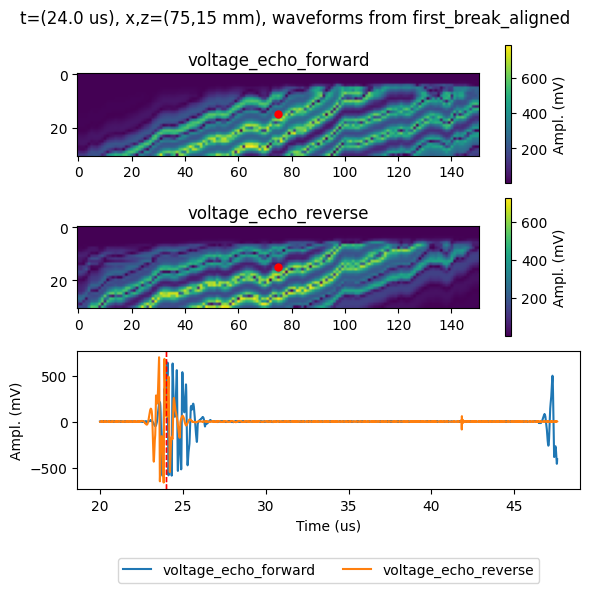

In [81]:
# check that alignment is right. You can look at waveforms or hilbert.
database.view_img_plot(idx = (75,15,2000), from_group='first_break_aligned', from_dataset='waveforms')

## Basic ToF and Hilbert Amplitude

We can get some basic information from the preprocessed data and display it. We only need to run these functions ONCE

In [ ]:
database.write_tof_data(from_group='first_break_aligned')

Calculating ToF: 100%|██████████| 9362/9362 [00:01<00:00, 8619.58it/s] 

	Finished


In [82]:
database.write_amplitude_data(from_group='first_break_aligned')

Calculating Amplitude: 100%|██████████| 9362/9362 [00:01<00:00, 6904.84it/s]

	Finished


In [83]:
# look at the h5 database structure now
database.print_schema()

<HDF5 file "092226_dualroll_scan_1mm_multiplexer.h5" (mode r+)>
|--<HDF5 dataset "config_metadata": shape (), type "|O"> [0.00 MB]
|--<HDF5 group "/first_break_aligned" (5 members)>
|  |--<HDF5 dataset "amplitude": shape (2, 151, 31), type "<f4"> [0.04 MB]
|  |--<HDF5 dataset "hilbert": shape (2, 151, 31, 13795), type "<f4"> [492.66 MB]
|  |--<HDF5 dataset "tof": shape (2, 151, 31), type "<f4"> [0.04 MB]
|  |--<HDF5 dataset "waveforms": shape (2, 151, 31, 13795), type "<f4"> [492.66 MB]
|  |--<HDF5 dataset "x_corr": shape (2, 151, 31, 13795), type "<f4"> [492.66 MB]
|--<HDF5 group "/indexed_parameters" (2 members)>
|  |--<HDF5 dataset "collection_index": shape (151, 31), type "<f4"> [0.02 MB]
|  |--<HDF5 dataset "time_collected": shape (151, 31), type "<f4"> [0.02 MB]
|--<HDF5 group "/preprocessed_data" (2 members)>
|  |--<HDF5 dataset "hilbert": shape (2, 151, 31, 25000), type "<f4"> [892.83 MB]
|  |--<HDF5 dataset "waveforms": shape (2, 151, 31, 25000), type "<f4"> [892.83 MB]
|--<HD

/Users/xz498/Library/CloudStorage/OneDrive-DrexelUniversity/Chang Lab - Documents/General/Individual/Xinqiao Zhang/data_analysis/ultrasonic_ml/Notebooks/fft/../../src/ultrasonic_ml/data/acoustic_datasets.py:1745: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  idx : int


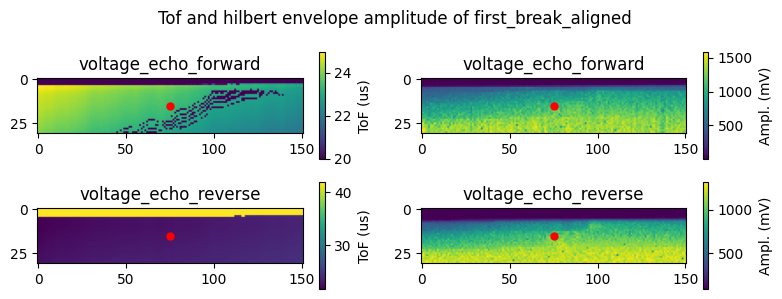

In [85]:
database.amplitude_tof_plot(idx=(75,15), from_group='first_break_aligned')

## Try correlation with mother waveform

### Autocorrelation

sliding dot product of a waveform with itself. Identifies repeating segments. May have extreme edge effects.

In [86]:
database.write_autocorrelation_data(from_group='first_break_aligned', mode='same')

Calculating Autocorrelation: 100%|██████████| 9362/9362 [00:09<00:00, 1014.50it/s]

	Finished


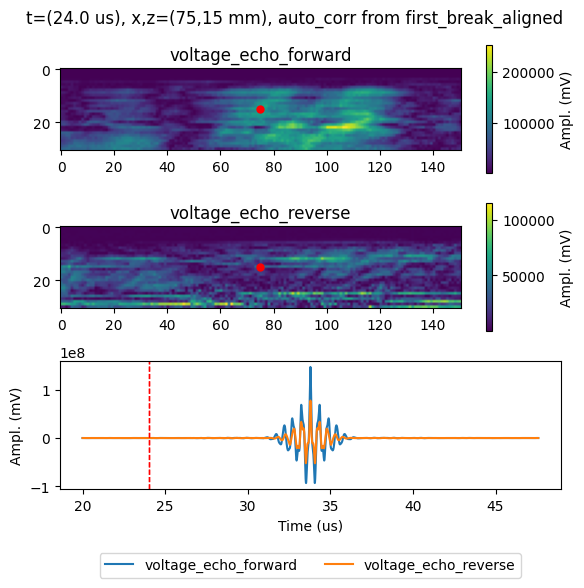

In [87]:
# As you can see, this might have extreme edge effects
database.view_img_plot(idx = (75,15,2000), from_group='first_break_aligned', from_dataset='auto_corr')

### Cross correlation

Sliding dot product of a waveform with another waveform. Convolution is with the flipped waveform, and is alternative implementation.
[Difference here.](https://towardsdatascience.com/convolution-vs-correlation-af868b6b4fb5/)

We can try cross-correlation using a mother waveform, such as the wave through the coupling fluid. The write_ function requires a path to the sqlite database for the mother waveform.

During setup, the mother wavelet will be interpolated to match the timestep of the current data.

In [88]:
water_sqlite_file = '/Users/xz498/Library/CloudStorage/OneDrive-DrexelUniversity/Chang Lab - Documents/General/Individual/Sam Amsterdam/acoustic scan data/tomography_testing/example_data/SA_tomography_test_water.sqlite3'

database.write_xcorrelation_data(mother_db_path=water_sqlite_file, from_group='first_break_aligned', mode='same')

Establishing SQLite connection to database...


Calculating Cross-correlation: 100%|██████████| 9362/9362 [00:10<00:00, 886.93it/s] 


	Finished


<string>:9: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


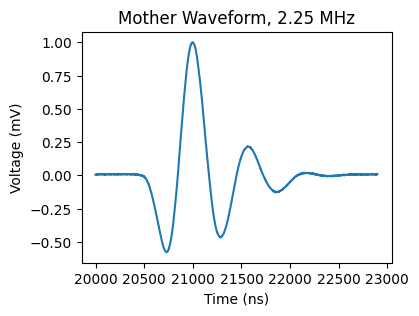

In [95]:
# Look at mother waveform:
database.view_mother_waveform(from_group='first_break_aligned')

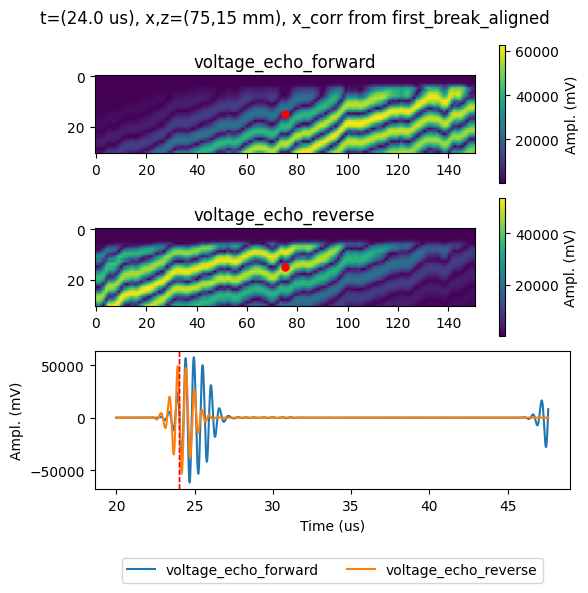

In [92]:
# x_correlation data is now written to the h5 file. Let's look at the data.
database.view_img_plot(idx = (75,15,2000), from_group='first_break_aligned', from_dataset='x_corr')

In [96]:
# look at the h5 database structure now
database.print_schema()

<HDF5 file "092226_dualroll_scan_1mm_multiplexer.h5" (mode r+)>
|--<HDF5 dataset "config_metadata": shape (), type "|O"> [0.00 MB]
|--<HDF5 group "/first_break_aligned" (6 members)>
|  |--<HDF5 dataset "amplitude": shape (2, 151, 31), type "<f4"> [0.04 MB]
|  |--<HDF5 dataset "auto_corr": shape (2, 151, 31, 13795), type "<f4"> [492.66 MB]
|  |--<HDF5 dataset "hilbert": shape (2, 151, 31, 13795), type "<f4"> [492.66 MB]
|  |--<HDF5 dataset "tof": shape (2, 151, 31), type "<f4"> [0.04 MB]
|  |--<HDF5 dataset "waveforms": shape (2, 151, 31, 13795), type "<f4"> [492.66 MB]
|  |--<HDF5 dataset "x_corr": shape (2, 151, 31, 13795), type "<f4"> [492.66 MB]
|--<HDF5 group "/indexed_parameters" (2 members)>
|  |--<HDF5 dataset "collection_index": shape (151, 31), type "<f4"> [0.02 MB]
|  |--<HDF5 dataset "time_collected": shape (151, 31), type "<f4"> [0.02 MB]
|--<HDF5 group "/preprocessed_data" (2 members)>
|  |--<HDF5 dataset "hilbert": shape (2, 151, 31, 25000), type "<f4"> [892.83 MB]
|  |--

## Calculate FFT

In [ ]:
# RUN ONCE
# align forward and reverse waveforms to first break and save to h5.
database.write_fft_data(from_group='first_break_aligned', from_dataset='waveforms', mode='full')

Computing FFT: 100%|██████████| 9362/9362 [00:19<00:00, 484.12it/s]


	Finished


<Figure size 640x480 with 0 Axes>

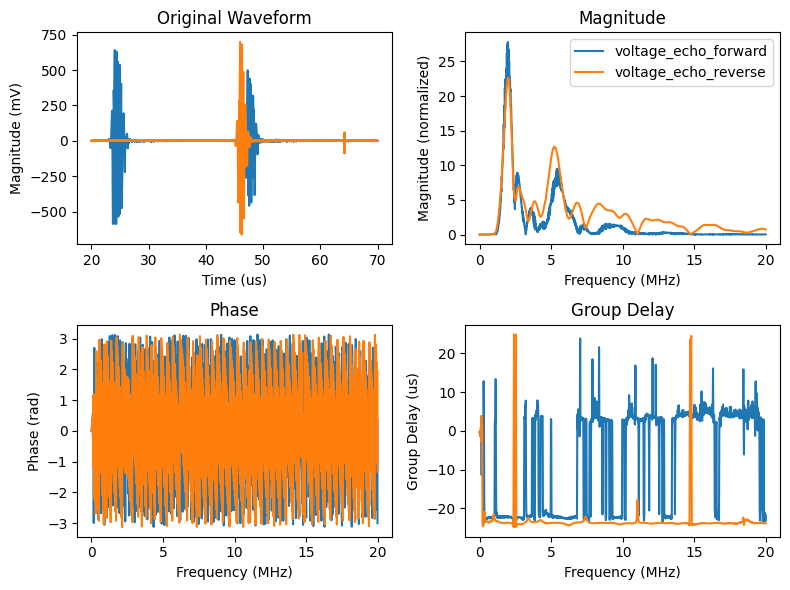

In [81]:
database.view_fft_plots(idx=(75,15), crop=[0, 1000], from_group='preprocessed_data') #TODO: check

In [82]:
# look at the h5 database structure now
database.print_schema()

<HDF5 file "092226_dualroll_scan_1mm_multiplexer.h5" (mode r+)>
|--<HDF5 dataset "config_metadata": shape (), type "|O">
|--<HDF5 group "/first_break_aligned" (5 members)>
|  |--<HDF5 dataset "amplitude": shape (2, 151, 31), type "<f4">
|  |--<HDF5 dataset "hilbert": shape (2, 151, 31, 13795), type "<f4">
|  |--<HDF5 dataset "tof": shape (2, 151, 31), type "<f4">
|  |--<HDF5 dataset "waveforms": shape (2, 151, 31, 13795), type "<f4">
|  |--<HDF5 dataset "x_corr": shape (2, 151, 31, 13795), type "<f4">
|--<HDF5 group "/indexed_parameters" (2 members)>
|  |--<HDF5 dataset "collection_index": shape (151, 31), type "<f4">
|  |--<HDF5 dataset "time_collected": shape (151, 31), type "<f4">
|--<HDF5 group "/preprocessed_data" (7 members)>
|  |--<HDF5 dataset "amplitude": shape (2, 151, 31), type "<f4">
|  |--<HDF5 dataset "auto_corr": shape (2, 151, 31, 25000), type "<f4">
|  |--<HDF5 dataset "fft_data": shape (2, 151, 31, 12501), type "<c8">
|  |--<HDF5 dataset "hilbert": shape (2, 151, 31, 

## Interactive visualizer

We can launch the interactive visualizer on a web browser. Interact on the browser, then press enter in the python prompt when complete

In [91]:
from ultrasonic_ml.viz import acoustic_viewers as viz

viz.AcousticScanViewerFFT.launch(db=database, from_group='preprocessed_data', aspect_ratio=6, crop = [0,1500])

Opening FFT datasets from group: preprocessed_data
Launching server at http://localhost:63911


Invoked as spatial_renderer(current_y=13655, current_x=75, current_z=15, dataset='tof', x=75, y=15)
Invoked as dynamic_operation(current_y=13655, current_x=75, current_z=15, dataset='tof', x=75, y=15)
Invoked as spatial_renderer(current_y=13655, current_x=75, current_z=15, dataset='tof', x=75, y=15)
Invoked as dynamic_operation(current_y=13655, current_x=75, current_z=15, dataset='tof', x=75, y=15)


Traceback (most recent call last):
  File "/Users/xz498/Applications/anaconda3/envs/ultrasound/lib/python3.14/site-packages/holoviews/plotting/util.py", line 319, in get_plot_frame
    return map_obj[key]
           ~~~~~~~^^^^^
  File "/Users/xz498/Applications/anaconda3/envs/ultrasound/lib/python3.14/site-packages/holoviews/core/spaces.py", line 1368, in __getitem__
    val = self._execute_callback(*tuple_key)
  File "/Users/xz498/Applications/anaconda3/envs/ultrasound/lib/python3.14/site-packages/holoviews/core/spaces.py", line 1118, in _execute_callback
    retval = self.callback(*args, **kwargs)
  File "/Users/xz498/Applications/anaconda3/envs/ultrasound/lib/python3.14/site-packages/holoviews/core/spaces.py", line 675, in __call__
    ret = self.callable(*args, **kwargs)
  File "/Users/xz498/Applications/anaconda3/envs/ultrasound/lib/python3.14/site-packages/holoviews/util/__init__.py", line 1135, in dynamic_operation
    key, obj = resolve(key, kwargs)
               ~~~~~~~^^^^^

Invoked as spatial_renderer(current_y=2274, current_x=75, current_z=15, dataset='tof', x=75, y=15)
Invoked as dynamic_operation(current_y=2274, current_x=75, current_z=15, dataset='tof', x=75, y=15)
Invoked as spatial_renderer(current_y=2274, current_x=75, current_z=15, dataset='tof', x=75, y=15)
Invoked as dynamic_operation(current_y=2274, current_x=75, current_z=15, dataset='tof', x=75, y=15)


Traceback (most recent call last):
  File "/Users/xz498/Applications/anaconda3/envs/ultrasound/lib/python3.14/site-packages/holoviews/plotting/util.py", line 319, in get_plot_frame
    return map_obj[key]
           ~~~~~~~^^^^^
  File "/Users/xz498/Applications/anaconda3/envs/ultrasound/lib/python3.14/site-packages/holoviews/core/spaces.py", line 1368, in __getitem__
    val = self._execute_callback(*tuple_key)
  File "/Users/xz498/Applications/anaconda3/envs/ultrasound/lib/python3.14/site-packages/holoviews/core/spaces.py", line 1118, in _execute_callback
    retval = self.callback(*args, **kwargs)
  File "/Users/xz498/Applications/anaconda3/envs/ultrasound/lib/python3.14/site-packages/holoviews/core/spaces.py", line 675, in __call__
    ret = self.callable(*args, **kwargs)
  File "/Users/xz498/Applications/anaconda3/envs/ultrasound/lib/python3.14/site-packages/holoviews/util/__init__.py", line 1135, in dynamic_operation
    key, obj = resolve(key, kwargs)
               ~~~~~~~^^^^^